In [1]:
from __future__ import annotations

import argparse
import json
import math
import re
from pathlib import Path

import cv2
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

try:
    import rawpy
except ImportError:  # reported clearly when repeat analysis is requested
    rawpy = None


DEPTH_GROUND_TRUTH = {
    "lf_train_01": 1810.0,
    "lf_train_02": 1100.0,
    "lf_train_03": 1400.0,
    "lf_train_04": 1600.0,
    "lf_holdout_01": 1300.0,
    "lf_holdout_02": 1500.0,
    "lf_holdout_03": 1200.0,
    "lf_holdout_04": 1700.0,
}

VIEW_CONFIGS = {
    3: [0, 4, 9],
    5: [0, 2, 4, 7, 9],
    7: [0, 2, 3, 4, 6, 8, 9],
    10: list(range(10)),
}

BASELINE_CONFIGS = {
    40: [4, 5, 6],
    80: [3, 5, 7],
    120: [2, 5, 8],
    160: [1, 5, 9],
}

TEMPLATE_ROI_XYXY = (235, 535, 390, 720)
POSITION_RE = re.compile(r"_x(?P<x>[+-]\d+(?:\.\d+)?)mm_", re.IGNORECASE)


def load_preview_views(session_dir: Path) -> tuple[list[np.ndarray], np.ndarray, list[Path]]:
    pngs = list((session_dir / "previews").glob("*.png"))
    if not pngs:
        pngs = list(session_dir.rglob("*.png"))

    parsed = []
    for path in pngs:
        match = POSITION_RE.search(path.name)
        if match:
            parsed.append((float(match.group("x")), path))
    parsed.sort(key=lambda item: item[0])

    if len(parsed) != 10:
        raise ValueError(f"{session_dir.name}: expected 10 position previews, found {len(parsed)}")

    positions = np.array([item[0] for item in parsed], dtype=np.float64)
    expected = np.arange(0.0, 200.0, 20.0)
    if not np.allclose(positions, expected):
        raise ValueError(f"{session_dir.name}: positions {positions.tolist()} do not match 0..180 mm")

    paths = [item[1] for item in parsed]
    images = [np.asarray(Image.open(path).convert("RGB")) for path in paths]
    shapes = {image.shape for image in images}
    if len(shapes) != 1:
        raise ValueError(f"{session_dir.name}: preview shapes differ: {sorted(shapes)}")
    return images, positions, paths


def estimate_disparity_slope(
    session_dir: Path,
    indices: list[int] | None = None,
) -> tuple[dict, pd.DataFrame]:
    images, positions, paths = load_preview_views(session_dir)
    if indices is None:
        indices = list(range(len(images)))
    if len(indices) < 3:
        raise ValueError("At least three views are required for a diagnostic linear fit")

    ref_index = int(np.argmin(np.abs(positions - 100.0)))
    x1, y1, x2, y2 = TEMPLATE_ROI_XYXY
    template = images[ref_index][y1:y2, x1:x2]
    if template.size == 0:
        raise ValueError(f"{session_dir.name}: template ROI is outside the preview")
    template_gray = cv2.cvtColor(template, cv2.COLOR_RGB2GRAY)

    rows = []
    for index in indices:
        gray = cv2.cvtColor(images[index], cv2.COLOR_RGB2GRAY)
        response = cv2.matchTemplate(gray, template_gray, cv2.TM_CCOEFF_NORMED)
        _, score, _, location = cv2.minMaxLoc(response)
        x_match, y_match = location
        rows.append(
            {
                "session": session_dir.name,
                "view_index": index,
                "camera_x_mm": positions[index],
                "object_x_px": float(x_match),
                "object_y_px": float(y_match),
                "match_score": float(score),
                "preview_file": paths[index].name,
            }
        )

    matches = pd.DataFrame(rows)
    slope, intercept = np.polyfit(matches["camera_x_mm"], matches["object_x_px"], 1)
    predicted = slope * matches["camera_x_mm"] + intercept
    residual = matches["object_x_px"] - predicted
    ss_res = float(np.sum(residual**2))
    ss_tot = float(np.sum((matches["object_x_px"] - matches["object_x_px"].mean()) ** 2))
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else math.nan
    matches["predicted_object_x_px"] = predicted
    matches["residual_px"] = residual

    result = {
        "session": session_dir.name,
        "split": "calibration" if "train" in session_dir.name else "holdout",
        "depth_mm": DEPTH_GROUND_TRUTH[session_dir.name],
        "n_views": len(indices),
        "baseline_mm": float(matches["camera_x_mm"].max() - matches["camera_x_mm"].min()),
        "indices_used": json.dumps(indices),
        "slope_px_per_mm": float(slope),
        "abs_slope_px_per_mm": float(abs(slope)),
        "intercept_px": float(intercept),
        "fit_R2": r2,
        "min_match_score": float(matches["match_score"].min()),
        "median_match_score": float(matches["match_score"].median()),
        "residual_RMSE_px": float(np.sqrt(np.mean(residual**2))),
        "max_abs_residual_px": float(np.max(np.abs(residual))),
    }
    return result, matches


def load_dng_gray_half(path: Path) -> np.ndarray:
    """Decode a DNG to an oriented half-resolution linear grayscale image."""
    if rawpy is None:
        raise RuntimeError("rawpy is required for DNG repeatability analysis")
    with rawpy.imread(str(path)) as raw:
        rgb = raw.postprocess(
            use_camera_wb=True,
            no_auto_bright=True,
            output_bps=8,
            gamma=(1, 1),
            half_size=True,
        )
    rgb = np.rot90(rgb, k=3)
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)


def quadratic_peak_offset(previous: float, centre: float, following: float) -> float:
    """Subpixel offset of a sampled parabolic peak, limited to one pixel."""
    denominator = previous - 2.0 * centre + following
    if abs(denominator) < 1e-12:
        return 0.0
    return float(np.clip(0.5 * (previous - following) / denominator, -1.0, 1.0))


def estimate_dng_repeat_slope(session_dir: Path, repeat_index: int) -> tuple[dict, pd.DataFrame]:
    manifest = pd.read_csv(session_dir / "manifest.csv")
    selected = manifest[manifest["repeat_index"] == repeat_index].sort_values("x_mm")
    if len(selected) != 10:
        raise ValueError(
            f"{session_dir.name} repeat {repeat_index}: expected 10 DNGs, found {len(selected)}"
        )
    positions = selected["x_mm"].to_numpy(float)
    paths = [session_dir / value for value in selected["filename"]]
    images = [load_dng_gray_half(path) for path in paths]

    preview_path = sorted((session_dir / "previews").glob("*.png"))[0]
    preview = np.asarray(Image.open(preview_path).convert("RGB"))
    scale_x = images[0].shape[1] / preview.shape[1]
    scale_y = images[0].shape[0] / preview.shape[0]
    x1, y1, x2, y2 = TEMPLATE_ROI_XYXY
    rx1, rx2 = int(round(x1 * scale_x)), int(round(x2 * scale_x))
    ry1, ry2 = int(round(y1 * scale_y)), int(round(y2 * scale_y))

    ref_index = int(np.argmin(np.abs(positions - 100.0)))
    template = images[ref_index][ry1:ry2, rx1:rx2]
    if template.size == 0:
        raise ValueError(f"{session_dir.name}: scaled RAW template ROI is empty")

    rows = []
    for view_index, (position, image, path) in enumerate(zip(positions, images, paths)):
        response = cv2.matchTemplate(image, template, cv2.TM_CCOEFF_NORMED)
        _, score, _, location = cv2.minMaxLoc(response)
        x_integer, y_integer = location
        x_offset = 0.0
        y_offset = 0.0
        if 0 < x_integer < response.shape[1] - 1:
            x_offset = quadratic_peak_offset(
                response[y_integer, x_integer - 1],
                response[y_integer, x_integer],
                response[y_integer, x_integer + 1],
            )
        if 0 < y_integer < response.shape[0] - 1:
            y_offset = quadratic_peak_offset(
                response[y_integer - 1, x_integer],
                response[y_integer, x_integer],
                response[y_integer + 1, x_integer],
            )
        x_match = x_integer + x_offset
        y_match = y_integer + y_offset
        rows.append(
            {
                "session": session_dir.name,
                "repeat_index": repeat_index,
                "view_index": view_index,
                "camera_x_mm": float(position),
                "object_x_px": float(x_match),
                "object_y_px": float(y_match),
                "object_x_integer_px": int(x_integer),
                "object_y_integer_px": int(y_integer),
                "subpixel_x_offset_px": x_offset,
                "subpixel_y_offset_px": y_offset,
                "match_score": float(score),
                "dng_file": path.name,
            }
        )

    matches = pd.DataFrame(rows)
    slope, intercept = np.polyfit(matches["camera_x_mm"], matches["object_x_px"], 1)
    predicted = slope * matches["camera_x_mm"] + intercept
    residual = matches["object_x_px"] - predicted
    ss_res = float(np.sum(residual**2))
    ss_tot = float(np.sum((matches["object_x_px"] - matches["object_x_px"].mean()) ** 2))
    matches["predicted_object_x_px"] = predicted
    matches["residual_px"] = residual
    result = {
        "session": session_dir.name,
        "split": "calibration" if "train" in session_dir.name else "holdout",
        "repeat_index": repeat_index,
        "depth_mm": DEPTH_GROUND_TRUTH[session_dir.name],
        "slope_px_per_mm_half_raw": float(slope),
        "abs_slope_px_per_mm_half_raw": float(abs(slope)),
        "intercept_px": float(intercept),
        "fit_R2": float(1.0 - ss_res / ss_tot),
        "min_match_score": float(matches["match_score"].min()),
        "residual_RMSE_px": float(np.sqrt(np.mean(residual**2))),
        "max_abs_residual_px": float(np.max(np.abs(residual))),
        "image_width_px": int(images[0].shape[1]),
        "preview_to_half_raw_scale": float(scale_x),
    }
    return result, matches


def run_dng_repeatability(lightfield_root: Path, output_dir: Path) -> dict:
    """Estimate depth independently for DNG repeats 1-3 and quantify repeatability."""
    slope_rows = []
    match_rows = []
    for session in DEPTH_GROUND_TRUTH:
        for repeat_index in (1, 2, 3):
            result, matches = estimate_dng_repeat_slope(
                lightfield_root / session, repeat_index
            )
            slope_rows.append(result)
            match_rows.append(matches)
    slopes = pd.DataFrame(slope_rows)
    matches = pd.concat(match_rows, ignore_index=True)

    train = slopes[slopes["split"] == "calibration"].copy()
    x = 1.0 / train["depth_mm"].to_numpy(float)
    y = train["abs_slope_px_per_mm_half_raw"].to_numpy(float)
    a_raw, b_raw = np.polyfit(x, y, 1)
    fitted = a_raw * x + b_raw
    ss_res = float(np.sum((y - fitted) ** 2))
    ss_tot = float(np.sum((y - y.mean()) ** 2))
    calibration_r2 = float(1.0 - ss_res / ss_tot)

    predictions = slopes[slopes["split"] == "holdout"].copy()
    predictions["estimated_depth_mm"] = a_raw / (
        predictions["abs_slope_px_per_mm_half_raw"] - b_raw
    )
    predictions["error_mm"] = predictions["estimated_depth_mm"] - predictions["depth_mm"]
    predictions["abs_error_mm"] = predictions["error_mm"].abs()
    predictions["percentage_error"] = (
        predictions["abs_error_mm"] / predictions["depth_mm"] * 100.0
    )

    repeat_summary = (
        predictions.groupby(["session", "depth_mm"], as_index=False)
        .agg(
            predicted_mean_mm=("estimated_depth_mm", "mean"),
            predicted_std_mm=("estimated_depth_mm", "std"),
            predicted_min_mm=("estimated_depth_mm", "min"),
            predicted_max_mm=("estimated_depth_mm", "max"),
            mean_error_mm=("error_mm", "mean"),
            mean_abs_error_mm=("abs_error_mm", "mean"),
        )
    )
    repeat_summary["range_mm"] = (
        repeat_summary["predicted_max_mm"] - repeat_summary["predicted_min_mm"]
    )

    centered = predictions["estimated_depth_mm"] - predictions.groupby("session")[
        "estimated_depth_mm"
    ].transform("mean")
    repeatability_sd = float(
        np.sqrt(np.sum(centered.to_numpy(float) ** 2) / (4 * (3 - 1)))
    )
    repeatability_limit = 2.77 * repeatability_sd
    all_metrics = metrics(predictions)
    aggregate = {
        "calibration_a_px_half_raw": float(a_raw),
        "calibration_b_px_per_mm_half_raw": float(b_raw),
        "calibration_R2": calibration_r2,
        **all_metrics,
        "within_depth_repeatability_SD_mm": repeatability_sd,
        "repeatability_limit_95_mm": float(repeatability_limit),
        "max_within_depth_range_mm": float(repeat_summary["range_mm"].max()),
        "min_match_score": float(slopes["min_match_score"].min()),
        "min_disparity_fit_R2": float(slopes["fit_R2"].min()),
    }

    slopes.to_csv(output_dir / "dng_repeat_slopes.csv", index=False)
    predictions.to_csv(output_dir / "dng_repeat_depth_predictions.csv", index=False)
    repeat_summary.to_csv(output_dir / "dng_repeatability_by_depth.csv", index=False)
    matches.to_csv(output_dir / "dng_repeat_all_matches.csv", index=False)
    pd.DataFrame([aggregate]).to_csv(output_dir / "dng_repeatability_metrics.csv", index=False)

    fig, ax = plt.subplots(figsize=(8.2, 5.2))
    sessions = list(predictions["session"].drop_duplicates())
    x_positions = np.arange(len(sessions))
    rng = np.random.default_rng(5720)
    for repeat_index, marker in zip((1, 2, 3), ("o", "s", "^")):
        subset = predictions[predictions["repeat_index"] == repeat_index].set_index("session")
        values = [subset.loc[name, "estimated_depth_mm"] for name in sessions]
        ax.scatter(x_positions + rng.normal(0, 0.025, len(sessions)), values,
                   marker=marker, s=62, label=f"DNG repeat {repeat_index}")
    true_values = [DEPTH_GROUND_TRUTH[name] for name in sessions]
    ax.scatter(x_positions, true_values, marker="_", s=260, linewidths=2.5,
               color="black", label="Measured depth")
    ax.set_xticks(x_positions, [name.replace("lf_", "") for name in sessions], rotation=25)
    ax.set(xlabel="Holdout session", ylabel="Estimated depth (mm)",
           title="Depth estimates from three independent DNG repeats")
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / "07_dng_repeat_depth_estimates.png", dpi=220)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8.2, 5.0))
    for repeat_index, marker in zip((1, 2, 3), ("o", "s", "^")):
        subset = predictions[predictions["repeat_index"] == repeat_index]
        ax.plot(subset["session"].str.replace("lf_", "", regex=False), subset["error_mm"],
                marker=marker, label=f"DNG repeat {repeat_index}")
    ax.axhline(0, color="black", linewidth=1)
    ax.set(xlabel="Holdout session", ylabel="Estimated − measured depth (mm)",
           title="Depth error by DNG repeat")
    ax.tick_params(axis="x", rotation=25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / "08_dng_repeat_depth_errors.png", dpi=220)
    plt.close(fig)
    return aggregate


def fit_calibration(rows: pd.DataFrame) -> dict:
    train = rows[rows["split"] == "calibration"].copy()
    x = 1.0 / train["depth_mm"].to_numpy(float)
    y = train["abs_slope_px_per_mm"].to_numpy(float)
    a, b = np.polyfit(x, y, 1)
    fitted = a * x + b
    ss_res = float(np.sum((y - fitted) ** 2))
    ss_tot = float(np.sum((y - y.mean()) ** 2))
    return {
        "a_px": float(a),
        "b_px_per_mm": float(b),
        "calibration_R2": float(1.0 - ss_res / ss_tot),
    }


def predict_holdout(rows: pd.DataFrame, model: dict) -> pd.DataFrame:
    holdout = rows[rows["split"] == "holdout"].copy()
    denominator = holdout["abs_slope_px_per_mm"] - model["b_px_per_mm"]
    holdout["estimated_depth_mm"] = model["a_px"] / denominator
    holdout["error_mm"] = holdout["estimated_depth_mm"] - holdout["depth_mm"]
    holdout["abs_error_mm"] = holdout["error_mm"].abs()
    holdout["percentage_error"] = holdout["abs_error_mm"] / holdout["depth_mm"] * 100.0
    return holdout


def metrics(predictions: pd.DataFrame) -> dict:
    errors = predictions["error_mm"].to_numpy(float)
    return {
        "n_holdout": int(len(errors)),
        "RMSE_mm": float(np.sqrt(np.mean(errors**2))),
        "MAE_mm": float(np.mean(np.abs(errors))),
        "MAPE_percent": float(np.mean(predictions["percentage_error"])),
        "bias_mm": float(np.mean(errors)),
        "max_abs_error_mm": float(np.max(np.abs(errors))),
    }


def bootstrap_metric_ci(
    predictions: pd.DataFrame,
    n_boot: int = 10000,
    seed: int = 5720,
) -> dict:
    errors = predictions["error_mm"].to_numpy(float)
    true_depth = predictions["depth_mm"].to_numpy(float)
    rng = np.random.default_rng(seed)
    sampled = rng.integers(0, len(errors), size=(n_boot, len(errors)))
    boot_errors = errors[sampled]
    boot_true = true_depth[sampled]
    values = {
        "RMSE": np.sqrt(np.mean(boot_errors**2, axis=1)),
        "MAE": np.mean(np.abs(boot_errors), axis=1),
        "MAPE": np.mean(np.abs(boot_errors) / boot_true * 100.0, axis=1),
    }
    result = {}
    for name, series in values.items():
        low, high = np.percentile(series, [2.5, 97.5])
        result[f"{name}_CI95_low"] = float(low)
        result[f"{name}_CI95_high"] = float(high)
    return result


def evaluate_configuration(
    lightfield_root: Path,
    indices: list[int],
    match_cache: dict[str, pd.DataFrame] | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame, dict, pd.DataFrame, dict]:
    results = []
    matches = []
    for session in DEPTH_GROUND_TRUTH:
        if match_cache is None:
            row, match_rows = estimate_disparity_slope(lightfield_root / session, indices)
        else:
            selected = match_cache[session]
            selected = selected[selected["view_index"].isin(indices)].copy()
            slope, intercept = np.polyfit(selected["camera_x_mm"], selected["object_x_px"], 1)
            predicted = slope * selected["camera_x_mm"] + intercept
            residual = selected["object_x_px"] - predicted
            ss_res = float(np.sum(residual**2))
            ss_tot = float(np.sum((selected["object_x_px"] - selected["object_x_px"].mean()) ** 2))
            selected["predicted_object_x_px"] = predicted
            selected["residual_px"] = residual
            row = {
                "session": session,
                "split": "calibration" if "train" in session else "holdout",
                "depth_mm": DEPTH_GROUND_TRUTH[session],
                "n_views": len(indices),
                "baseline_mm": float(selected["camera_x_mm"].max() - selected["camera_x_mm"].min()),
                "indices_used": json.dumps(indices),
                "slope_px_per_mm": float(slope),
                "abs_slope_px_per_mm": float(abs(slope)),
                "intercept_px": float(intercept),
                "fit_R2": float(1.0 - ss_res / ss_tot),
                "min_match_score": float(selected["match_score"].min()),
                "median_match_score": float(selected["match_score"].median()),
                "residual_RMSE_px": float(np.sqrt(np.mean(residual**2))),
                "max_abs_residual_px": float(np.max(np.abs(residual))),
            }
            match_rows = selected
        results.append(row)
        matches.append(match_rows)
    slopes = pd.DataFrame(results)
    model = fit_calibration(slopes)
    predictions = predict_holdout(slopes, model)
    summary = metrics(predictions) | bootstrap_metric_ci(predictions)
    return slopes, predictions, model, pd.concat(matches, ignore_index=True), summary


def save_plots(
    output_dir: Path,
    slopes: pd.DataFrame,
    predictions: pd.DataFrame,
    model: dict,
    view_metrics: pd.DataFrame,
    baseline_metrics: pd.DataFrame,
) -> None:
    plt.style.use("seaborn-v0_8-whitegrid")

    fig, ax = plt.subplots(figsize=(8.2, 5.4))
    train = slopes[slopes["split"] == "calibration"]
    holdout = slopes[slopes["split"] == "holdout"]
    depth_curve = np.linspace(1000, 1900, 400)
    slope_curve = model["a_px"] / depth_curve + model["b_px_per_mm"]
    ax.scatter(train["depth_mm"], train["abs_slope_px_per_mm"], s=70, label="Calibration")
    ax.scatter(holdout["depth_mm"], holdout["abs_slope_px_per_mm"], s=70, label="Holdout")
    ax.plot(depth_curve, slope_curve, color="black", label="Fit on calibration set")
    ax.set(xlabel="Measured depth (mm)", ylabel="Absolute disparity slope (px/mm)",
           title="Disparity slope and measured depth")
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / "01_disparity_slope_vs_depth.png", dpi=220)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(6.5, 6.2))
    ax.scatter(predictions["depth_mm"], predictions["estimated_depth_mm"], s=75)
    limits = [
        min(predictions["depth_mm"].min(), predictions["estimated_depth_mm"].min()) - 30,
        max(predictions["depth_mm"].max(), predictions["estimated_depth_mm"].max()) + 30,
    ]
    ax.plot(limits, limits, "k--", label="Ideal: estimated = measured")
    for row in predictions.itertuples():
        ax.annotate(row.session, (row.depth_mm, row.estimated_depth_mm), xytext=(5, 5),
                    textcoords="offset points", fontsize=8)
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="Measured depth (mm)",
           ylabel="Estimated depth (mm)", title="Independent holdout depth validation")
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / "02_estimated_vs_measured_depth.png", dpi=220)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7.6, 5.0))
    yerr = np.vstack([
        view_metrics["RMSE_mm"] - view_metrics["RMSE_CI95_low"],
        view_metrics["RMSE_CI95_high"] - view_metrics["RMSE_mm"],
    ])
    ax.errorbar(view_metrics["n_views"], view_metrics["RMSE_mm"], yerr=yerr,
                marker="o", capsize=4)
    ax.set(xlabel="Number of viewpoints", ylabel="Holdout depth RMSE (mm)",
           title="Depth error and viewpoint count")
    fig.tight_layout()
    fig.savefig(output_dir / "03_depth_rmse_vs_viewpoint_count.png", dpi=220)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7.6, 5.0))
    yerr = np.vstack([
        baseline_metrics["RMSE_mm"] - baseline_metrics["RMSE_CI95_low"],
        baseline_metrics["RMSE_CI95_high"] - baseline_metrics["RMSE_mm"],
    ])
    ax.errorbar(baseline_metrics["baseline_mm"], baseline_metrics["RMSE_mm"], yerr=yerr,
                marker="o", capsize=4)
    ax.set(xlabel="Synthetic-aperture baseline (mm)", ylabel="Holdout depth RMSE (mm)",
           title="Depth error and baseline (3 viewpoints)")
    fig.tight_layout()
    fig.savefig(output_dir / "04_depth_rmse_vs_baseline.png", dpi=220)
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
    labels = slopes["session"].str.replace("lf_", "", regex=False)
    axes[0].bar(labels, slopes["fit_R2"])
    axes[0].set_ylim(min(0.9995, slopes["fit_R2"].min() - 0.00005), 1.00002)
    axes[0].set_title("Disparity linear-fit R²")
    axes[0].tick_params(axis="x", rotation=55)
    axes[1].bar(labels, slopes["min_match_score"])
    axes[1].set_ylim(min(0.94, slopes["min_match_score"].min() - 0.01), 1.0)
    axes[1].set_title("Minimum template-match score")
    axes[1].tick_params(axis="x", rotation=55)
    fig.suptitle("Input matching diagnostics")
    fig.tight_layout()
    fig.savefig(output_dir / "05_matching_diagnostics.png", dpi=220)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7.6, 4.8))
    colors = ["#4C78A8" if value >= 0 else "#E45756" for value in predictions["error_mm"]]
    ax.bar(predictions["session"], predictions["error_mm"], color=colors)
    ax.axhline(0, color="black", linewidth=1)
    ax.set(xlabel="Holdout session", ylabel="Estimated − measured depth (mm)",
           title="Holdout depth residuals")
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    fig.savefig(output_dir / "06_holdout_depth_residuals.png", dpi=220)
    plt.close(fig)


def build_input_audit(lightfield_root: Path) -> pd.DataFrame:
    rows = []
    for session in DEPTH_GROUND_TRUTH:
        folder = lightfield_root / session
        manifest = pd.read_csv(folder / "manifest.csv")
        per_position = manifest.groupby("x_mm").size()
        exposure_values = sorted(manifest["exposure_us_requested"].dropna().unique().tolist())
        gain_values = sorted(manifest["gain_requested"].dropna().unique().tolist())
        issues = []
        if len(manifest) != 30:
            issues.append(f"manifest rows={len(manifest)}, expected 30")
        if manifest["x_mm"].nunique() != 10:
            issues.append(f"positions={manifest['x_mm'].nunique()}, expected 10")
        if per_position.min() != 3 or per_position.max() != 3:
            issues.append("not exactly 3 DNG repeats at every position")
        if len(list(folder.rglob("*.dng"))) != 30:
            issues.append("DNG count is not 30")
        if len(list(folder.rglob("*.png"))) != 10:
            issues.append("PNG preview count is not 10")
        if exposure_values != [32000]:
            issues.append(f"exposure values={exposure_values}")
        if gain_values != [4.0]:
            issues.append(f"gain values={gain_values}")
        rows.append(
            {
                "session": session,
                "manifest_rows": len(manifest),
                "positions": int(manifest["x_mm"].nunique()),
                "repeats_per_position_min": int(per_position.min()),
                "repeats_per_position_max": int(per_position.max()),
                "DNG_count": len(list(folder.rglob("*.dng"))),
                "PNG_preview_count": len(list(folder.rglob("*.png"))),
                "exposure_us_values": json.dumps(exposure_values),
                "gain_values": json.dumps(gain_values),
                "max_saturated_percent": float(manifest["saturated_pct"].max()),
                "max_near_black_percent": float(manifest["near_black_pct"].max()),
                "structural_QC": "PASS" if not issues else "FAIL",
                "issues": "; ".join(issues),
            }
        )
    return pd.DataFrame(rows)


def run_analysis(data_root: Path, output_dir: Path) -> dict:
    data_root = data_root.resolve()
    lightfield_root = data_root / "sessions" / "lightfield"
    output_dir.mkdir(parents=True, exist_ok=True)
    missing = [name for name in DEPTH_GROUND_TRUTH if not (lightfield_root / name).is_dir()]
    if missing:
        raise FileNotFoundError(f"Missing light-field sessions: {missing}")
    input_audit = build_input_audit(lightfield_root)

    slopes, predictions, model, all_matches, full_metrics = evaluate_configuration(
        lightfield_root, VIEW_CONFIGS[10]
    )
    match_cache = {
        session: all_matches[all_matches["session"] == session].copy()
        for session in DEPTH_GROUND_TRUTH
    }

    view_rows = []
    view_predictions = []
    for n_views, indices in VIEW_CONFIGS.items():
        cfg_slopes, cfg_predictions, cfg_model, _, cfg_metrics = evaluate_configuration(
            lightfield_root, indices, match_cache
        )
        row = {
            "n_views": n_views,
            "indices_used": json.dumps(indices),
            "positions_mm": json.dumps([int(i * 20) for i in indices]),
            "baseline_mm": int((max(indices) - min(indices)) * 20),
            **cfg_model,
            **cfg_metrics,
        }
        view_rows.append(row)
        cfg_predictions["configuration_n_views"] = n_views
        view_predictions.append(cfg_predictions)

    baseline_rows = []
    baseline_predictions = []
    for baseline_mm, indices in BASELINE_CONFIGS.items():
        cfg_slopes, cfg_predictions, cfg_model, _, cfg_metrics = evaluate_configuration(
            lightfield_root, indices, match_cache
        )
        row = {
            "baseline_mm": baseline_mm,
            "n_views": len(indices),
            "indices_used": json.dumps(indices),
            "positions_mm": json.dumps([int(i * 20) for i in indices]),
            **cfg_model,
            **cfg_metrics,
        }
        baseline_rows.append(row)
        cfg_predictions["configuration_baseline_mm"] = baseline_mm
        baseline_predictions.append(cfg_predictions)

    view_metrics = pd.DataFrame(view_rows)
    baseline_metrics = pd.DataFrame(baseline_rows)
    full_summary = pd.DataFrame([{"configuration": "10 views, 180 mm baseline", **model, **full_metrics}])

    slopes.to_csv(output_dir / "depth_slopes_and_diagnostics.csv", index=False)
    predictions.to_csv(output_dir / "holdout_depth_predictions.csv", index=False)
    full_summary.to_csv(output_dir / "summary_metrics.csv", index=False)
    view_metrics.to_csv(output_dir / "viewpoint_count_metrics.csv", index=False)
    baseline_metrics.to_csv(output_dir / "baseline_metrics.csv", index=False)
    pd.concat(view_predictions, ignore_index=True).to_csv(
        output_dir / "viewpoint_count_predictions.csv", index=False
    )
    pd.concat(baseline_predictions, ignore_index=True).to_csv(
        output_dir / "baseline_predictions.csv", index=False
    )
    all_matches.to_csv(output_dir / "all_view_matches.csv", index=False)
    input_audit.to_csv(output_dir / "input_data_audit.csv", index=False)

    save_plots(output_dir, slopes, predictions, model, view_metrics, baseline_metrics)
    dng_repeat_metrics = run_dng_repeatability(lightfield_root, output_dir)

    machine_summary = {
        "data_root": str(data_root),
        "output_dir": str(output_dir.resolve()),
        "calibration_model": model,
        "holdout_metrics": full_metrics,
        "best_tested_viewpoint_count": int(view_metrics.loc[view_metrics["RMSE_mm"].idxmin(), "n_views"]),
        "best_tested_baseline_mm": int(baseline_metrics.loc[baseline_metrics["RMSE_mm"].idxmin(), "baseline_mm"]),
        "dng_repeatability": dng_repeat_metrics,
    }
    (output_dir / "results_summary.json").write_text(
        json.dumps(machine_summary, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    return machine_summary


## Run the full analysis

In [2]:
from IPython.display import Image as DisplayImage, display

DATA_ROOT = Path.cwd()
if not (DATA_ROOT / 'sessions' / 'lightfield').is_dir():
    raise FileNotFoundError('Open this notebook from the final_experiment_data folder.')
OUTPUT_DIR = DATA_ROOT / 'boyuan_depth_results'
summary = run_analysis(DATA_ROOT, OUTPUT_DIR)
summary

{'data_root': 'C:\\Users\\user\\Desktop\\M2\\Sensors and Signals\\Major Project\\major project\\final_experiment_data',
 'output_dir': 'C:\\Users\\user\\Desktop\\M2\\Sensors and Signals\\Major Project\\major project\\final_experiment_data\\boyuan_depth_results',
 'calibration_model': {'a_px': 1802.4945828459258,
  'b_px_per_mm': 0.010971049475527177,
  'calibration_R2': 0.9998402433317203},
 'holdout_metrics': {'n_holdout': 4,
  'RMSE_mm': 7.985810252772587,
  'MAE_mm': 6.846387275547784,
  'MAPE_percent': 0.45176514738728785,
  'bias_mm': 6.846387275547784,
  'max_abs_error_mm': 13.301391300464502,
  'RMSE_CI95_low': 3.721291241547257,
  'RMSE_CI95_high': 11.764819035742775,
  'MAE_CI95_low': 3.424886814402157,
  'MAE_CI95_high': 11.171420931188266,
  'MAPE_CI95_low': 0.2558064081220702,
  'MAPE_CI95_high': 0.6787781987728825},
 'best_tested_viewpoint_count': 7,
 'best_tested_baseline_mm': 120,
 'dng_repeatability': {'calibration_a_px_half_raw': 1452.0996938722412,
  'calibration_b_px

## Main quantitative results

In [3]:
summary_metrics = pd.read_csv(OUTPUT_DIR / 'summary_metrics.csv')
holdout_predictions = pd.read_csv(OUTPUT_DIR / 'holdout_depth_predictions.csv')
display(summary_metrics)
display(holdout_predictions[['session', 'depth_mm', 'estimated_depth_mm', 'error_mm', 'abs_error_mm', 'percentage_error']])

,configuration,a_px,b_px_per_mm,calibration_R2,n_holdout,RMSE_mm,MAE_mm,MAPE_percent,bias_mm,max_abs_error_mm,RMSE_CI95_low,RMSE_CI95_high,MAE_CI95_low,MAE_CI95_high,MAPE_CI95_low,MAPE_CI95_high
0,"10 views, 180 mm baseline",1802.494583,0.010971,0.99984,4,7.98581,6.846387,0.451765,6.846387,13.301391,3.721291,11.764819,3.424887,11.171421,0.255806,0.678778


,session,depth_mm,estimated_depth_mm,error_mm,abs_error_mm,percentage_error
0,lf_holdout_01,1300.0,1304.781510,4.781510,4.781510,0.367808
1,lf_holdout_02,1500.0,1507.104198,7.104198,7.104198,0.473613
2,lf_holdout_03,1200.0,1202.198450,2.198450,2.198450,0.183204
3,lf_holdout_04,1700.0,1713.301391,13.301391,13.301391,0.782435


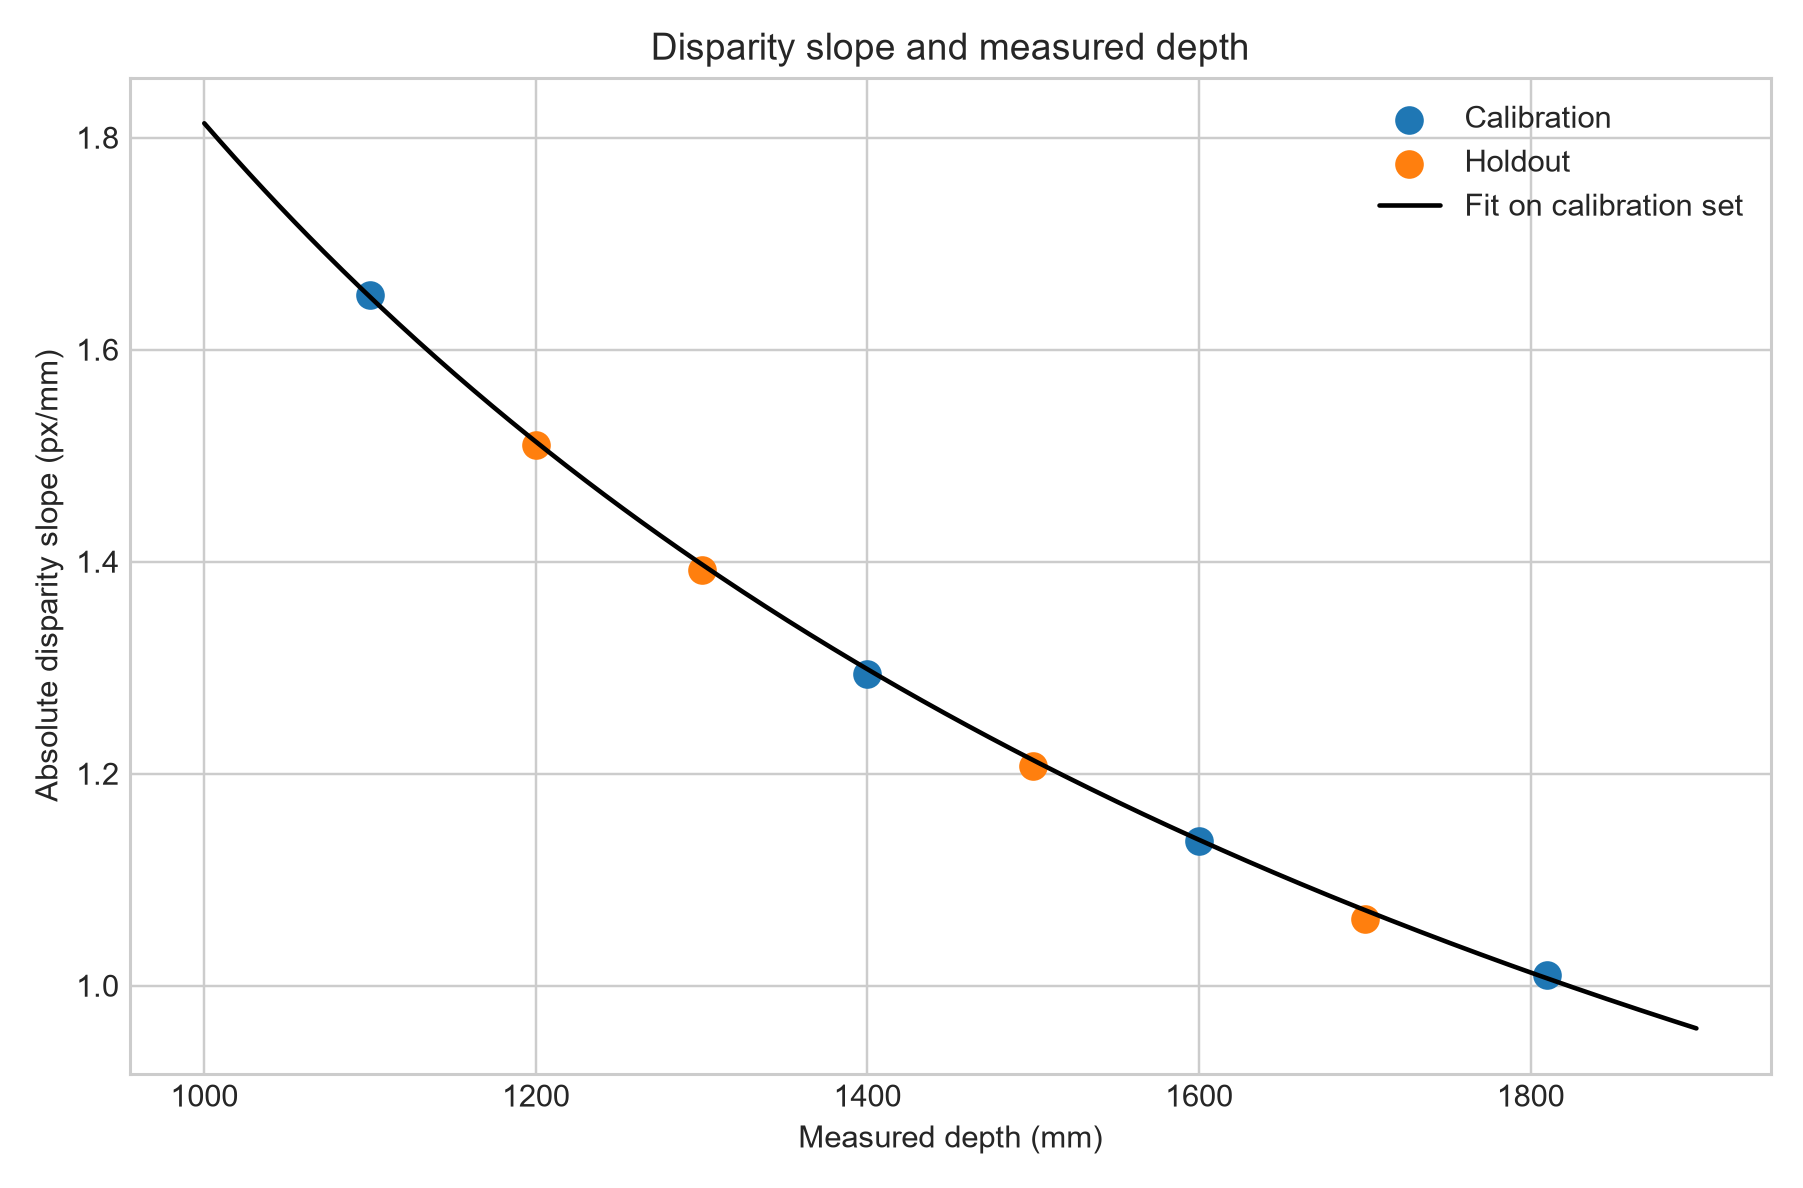

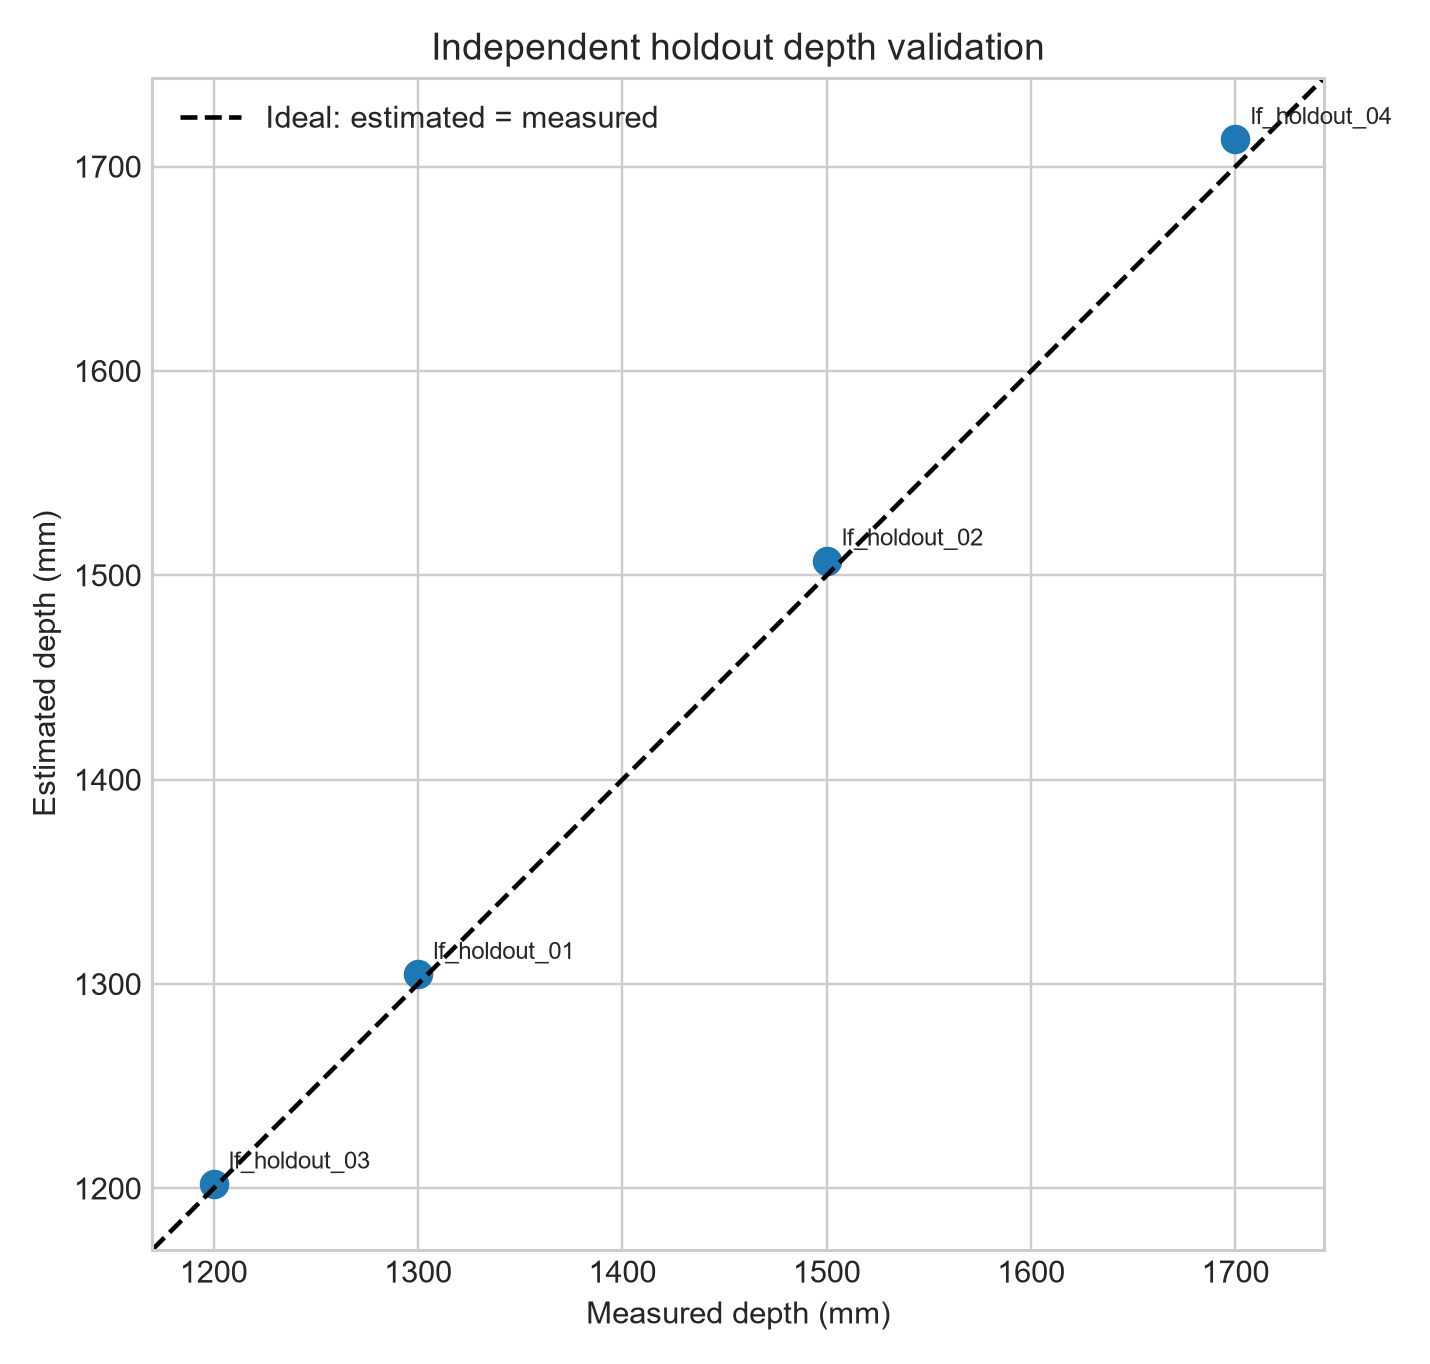

In [4]:
display(DisplayImage(filename=str(OUTPUT_DIR / '01_disparity_slope_vs_depth.png')))
display(DisplayImage(filename=str(OUTPUT_DIR / '02_estimated_vs_measured_depth.png')))

## Viewpoint-count and baseline effects

In [5]:
view_metrics = pd.read_csv(OUTPUT_DIR / 'viewpoint_count_metrics.csv')
baseline_metrics = pd.read_csv(OUTPUT_DIR / 'baseline_metrics.csv')
display(view_metrics[['n_views', 'positions_mm', 'RMSE_mm', 'MAE_mm', 'MAPE_percent', 'RMSE_CI95_low', 'RMSE_CI95_high']])
display(baseline_metrics[['baseline_mm', 'positions_mm', 'RMSE_mm', 'MAE_mm', 'MAPE_percent', 'RMSE_CI95_low', 'RMSE_CI95_high']])

,n_views,positions_mm,RMSE_mm,MAE_mm,MAPE_percent,RMSE_CI95_low,RMSE_CI95_high
0,3,"[0, 80, 180]",9.081841,7.378745,0.499680,3.736395,14.006756
1,5,"[0, 40, 80, 140, 180]",7.398501,6.500230,0.448525,3.571393,10.849662
2,7,"[0, 40, 60, 80, 120, 160, 180]",4.981898,4.220265,0.280360,2.412182,7.686325
3,10,"[0, 20, 40, 60, 80, 100, 120, 140, 160, 180]",7.985810,6.846387,0.451765,3.721291,11.764819


,baseline_mm,positions_mm,RMSE_mm,MAE_mm,MAPE_percent,RMSE_CI95_low,RMSE_CI95_high
0,40,"[80, 100, 120]",18.059132,15.172506,1.061271,7.564784,27.555223
1,80,"[60, 100, 140]",9.355032,7.318142,0.475507,3.423348,15.105976
2,120,"[40, 100, 160]",6.040329,5.547496,0.377620,3.509366,7.403613
3,160,"[20, 100, 180]",14.948904,11.225099,0.710242,3.433705,22.642200


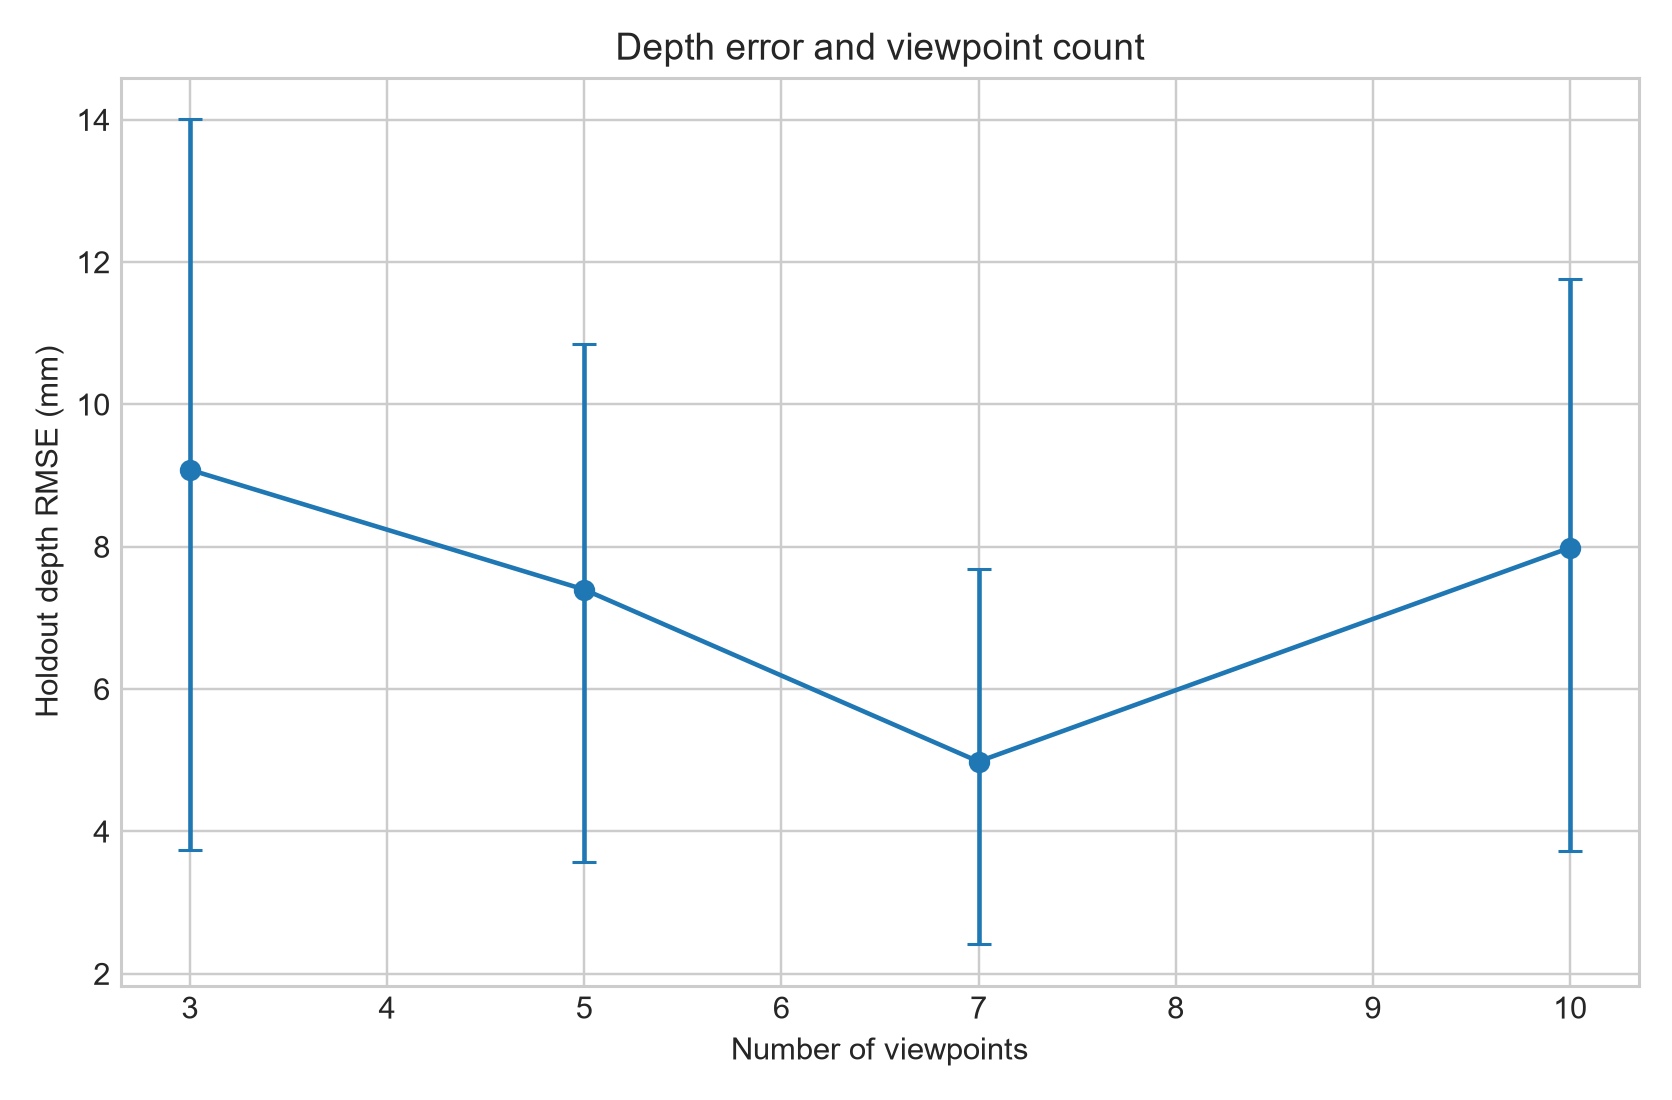

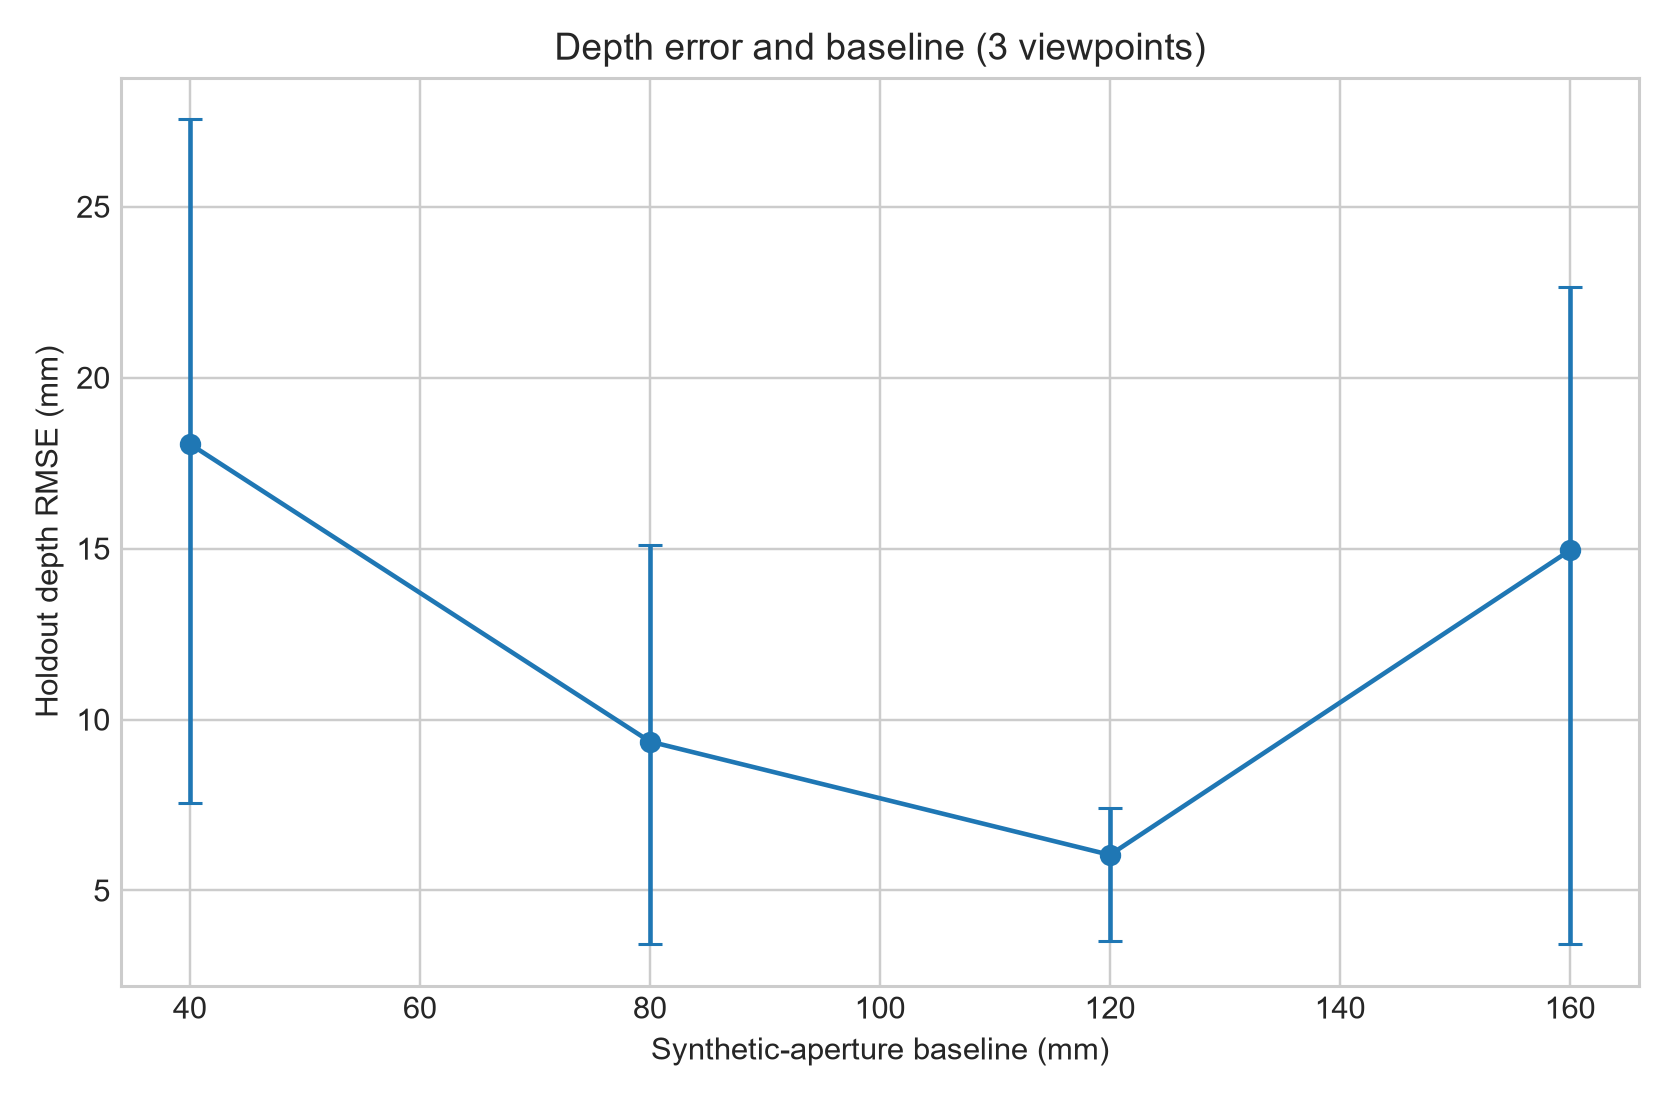

In [6]:
display(DisplayImage(filename=str(OUTPUT_DIR / '03_depth_rmse_vs_viewpoint_count.png')))
display(DisplayImage(filename=str(OUTPUT_DIR / '04_depth_rmse_vs_baseline.png')))

## Input matching diagnostics

,session,split,depth_mm,slope_px_per_mm,fit_R2,min_match_score,residual_RMSE_px,max_abs_residual_px
0,lf_train_01,calibration,1810.0,-1.010303,0.999760,0.968620,0.899832,1.509091
1,lf_train_02,calibration,1100.0,-1.651818,0.999975,0.963406,0.478634,0.654545
2,lf_train_03,calibration,1400.0,-1.294242,0.999931,0.971547,0.616933,1.042424
3,lf_train_04,calibration,1600.0,-1.136061,0.999878,0.967141,0.720269,1.503030
4,lf_holdout_01,holdout,1300.0,-1.392424,0.999953,0.970394,0.548276,0.824242
5,lf_holdout_02,holdout,1500.0,-1.206970,0.999906,0.974862,0.670594,1.072727
6,lf_holdout_03,holdout,1200.0,-1.510303,0.999972,0.971501,0.457927,0.903030
7,lf_holdout_04,holdout,1700.0,-1.063030,0.999922,0.970278,0.538235,0.890909


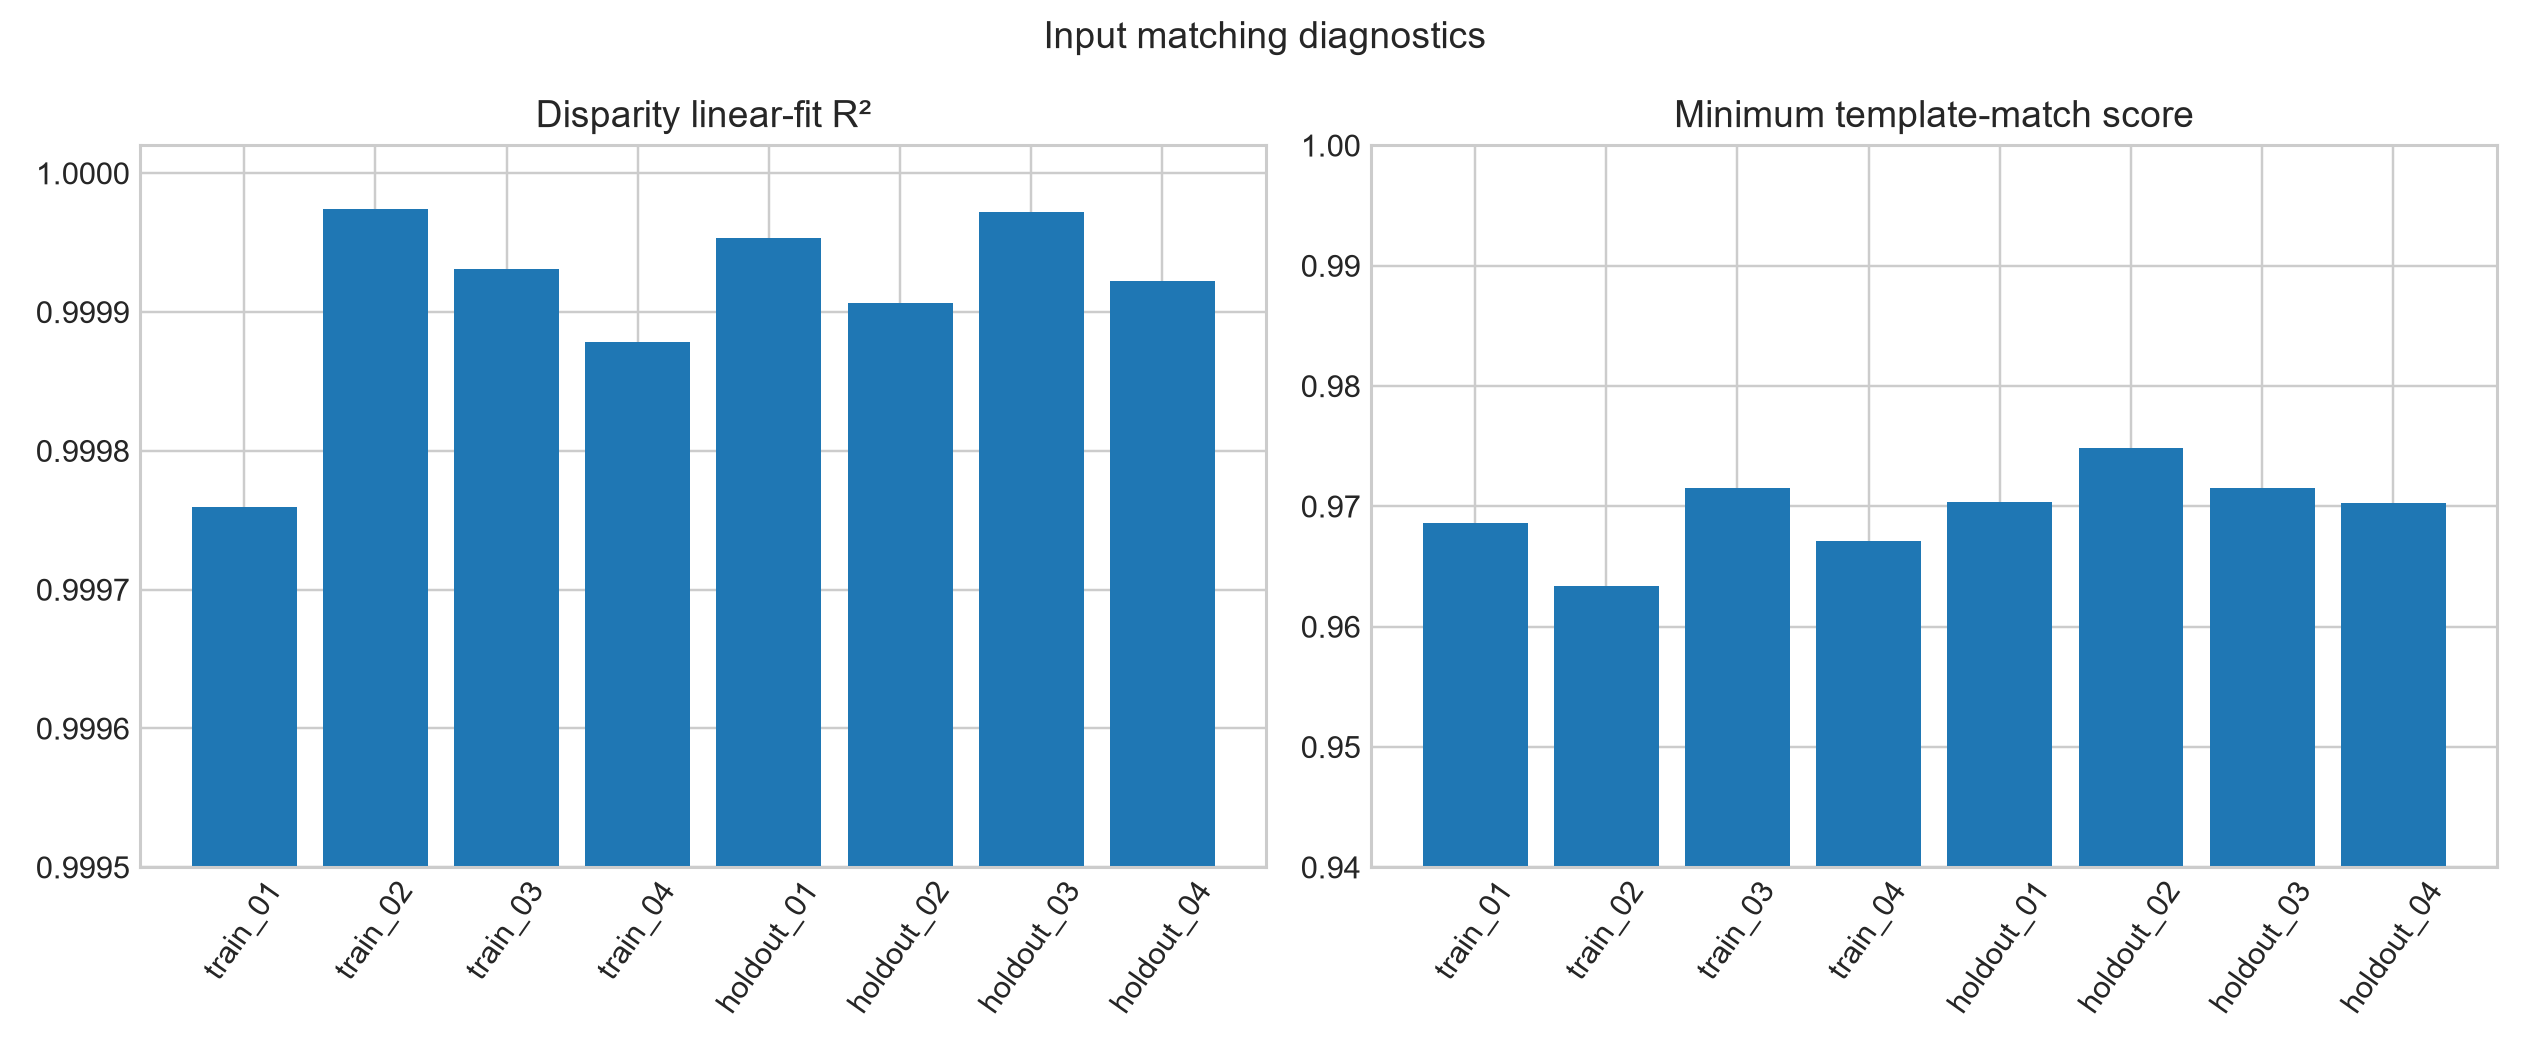

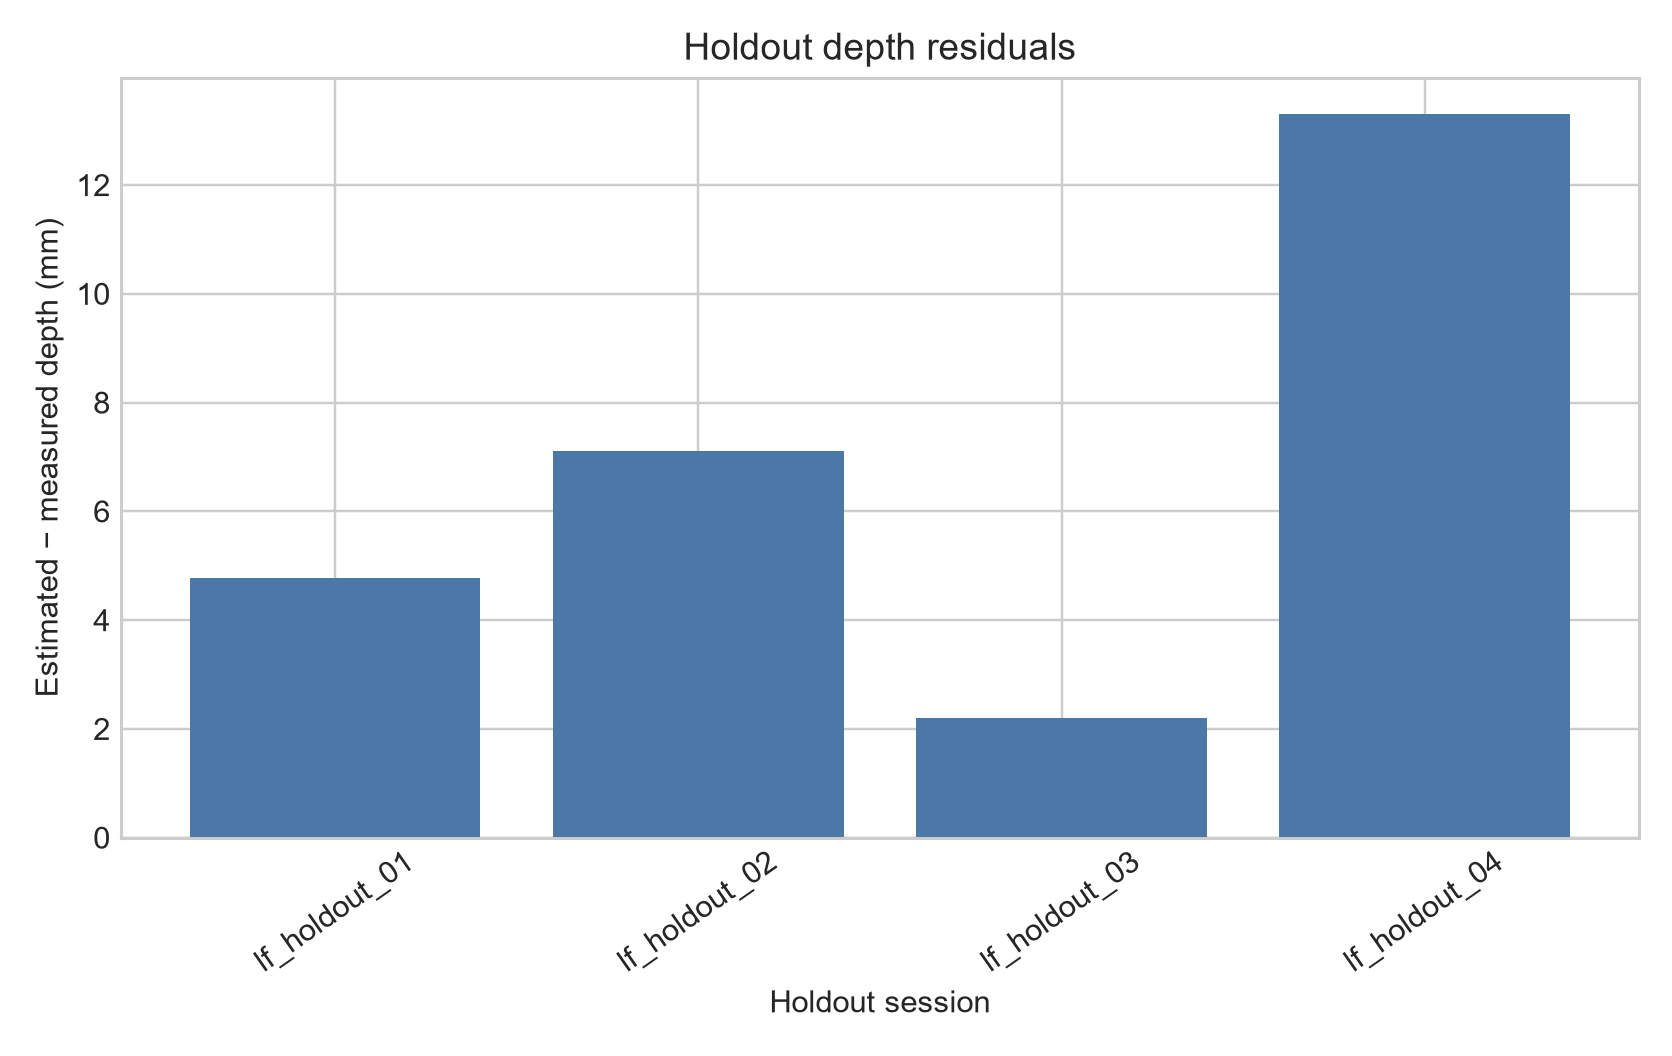

In [7]:
diagnostics = pd.read_csv(OUTPUT_DIR / 'depth_slopes_and_diagnostics.csv')
display(diagnostics[['session', 'split', 'depth_mm', 'slope_px_per_mm', 'fit_R2', 'min_match_score', 'residual_RMSE_px', 'max_abs_residual_px']])
display(DisplayImage(filename=str(OUTPUT_DIR / '05_matching_diagnostics.png')))
display(DisplayImage(filename=str(OUTPUT_DIR / '06_holdout_depth_residuals.png')))

## Three-repeat DNG depth repeatability

Each DNG repeat is decoded and processed independently. Subpixel template-match peak interpolation avoids rounding all three repeats to the same integer displacement. This section separates **precision/repeatability** from **absolute accuracy**.

In [8]:
dng_metrics = pd.read_csv(OUTPUT_DIR / 'dng_repeatability_metrics.csv')
dng_by_depth = pd.read_csv(OUTPUT_DIR / 'dng_repeatability_by_depth.csv')
dng_predictions = pd.read_csv(OUTPUT_DIR / 'dng_repeat_depth_predictions.csv')
display(dng_metrics)
display(dng_by_depth)
display(dng_predictions[['session', 'repeat_index', 'depth_mm', 'estimated_depth_mm', 'error_mm', 'fit_R2', 'min_match_score']])

,calibration_a_px_half_raw,calibration_b_px_per_mm_half_raw,calibration_R2,n_holdout,RMSE_mm,MAE_mm,MAPE_percent,bias_mm,max_abs_error_mm,within_depth_repeatability_SD_mm,repeatability_limit_95_mm,max_within_depth_range_mm,min_match_score,min_disparity_fit_R2
0,1452.099694,0.000888,0.999621,12,6.574942,5.796295,0.389469,5.796295,11.546648,0.462135,1.280113,1.463995,0.95,0.999864


,session,depth_mm,predicted_mean_mm,predicted_std_mm,predicted_min_mm,predicted_max_mm,mean_error_mm,mean_abs_error_mm,range_mm
0,lf_holdout_01,1300.0,1302.476968,0.161090,1302.328060,1302.647961,2.476968,2.476968,0.319902
1,lf_holdout_02,1500.0,1505.682845,0.456749,1505.331288,1506.199101,5.682845,5.682845,0.867813
2,lf_holdout_03,1200.0,1204.269306,0.271269,1204.012404,1204.552959,4.269306,4.269306,0.540555
3,lf_holdout_04,1700.0,1710.756062,0.738998,1710.082654,1711.546648,10.756062,10.756062,1.463995


,session,repeat_index,depth_mm,estimated_depth_mm,error_mm,fit_R2,min_match_score
0,lf_holdout_01,1,1300.0,1302.647961,2.647961,0.999963,0.956944
1,lf_holdout_01,2,1300.0,1302.454883,2.454883,0.999963,0.955848
2,lf_holdout_01,3,1300.0,1302.328060,2.328060,0.999963,0.959134
3,lf_holdout_02,1,1500.0,1505.518145,5.518145,0.999941,0.966085
4,lf_holdout_02,2,1500.0,1505.331288,5.331288,0.999944,0.964776
5,lf_holdout_02,3,1500.0,1506.199101,6.199101,0.999944,0.965926
6,lf_holdout_03,1,1200.0,1204.242554,4.242554,0.999977,0.957273
7,lf_holdout_03,2,1200.0,1204.012404,4.012404,0.999978,0.954764
8,lf_holdout_03,3,1200.0,1204.552959,4.552959,0.999974,0.954990
9,lf_holdout_04,1,1700.0,1710.082654,10.082654,0.999914,0.960409


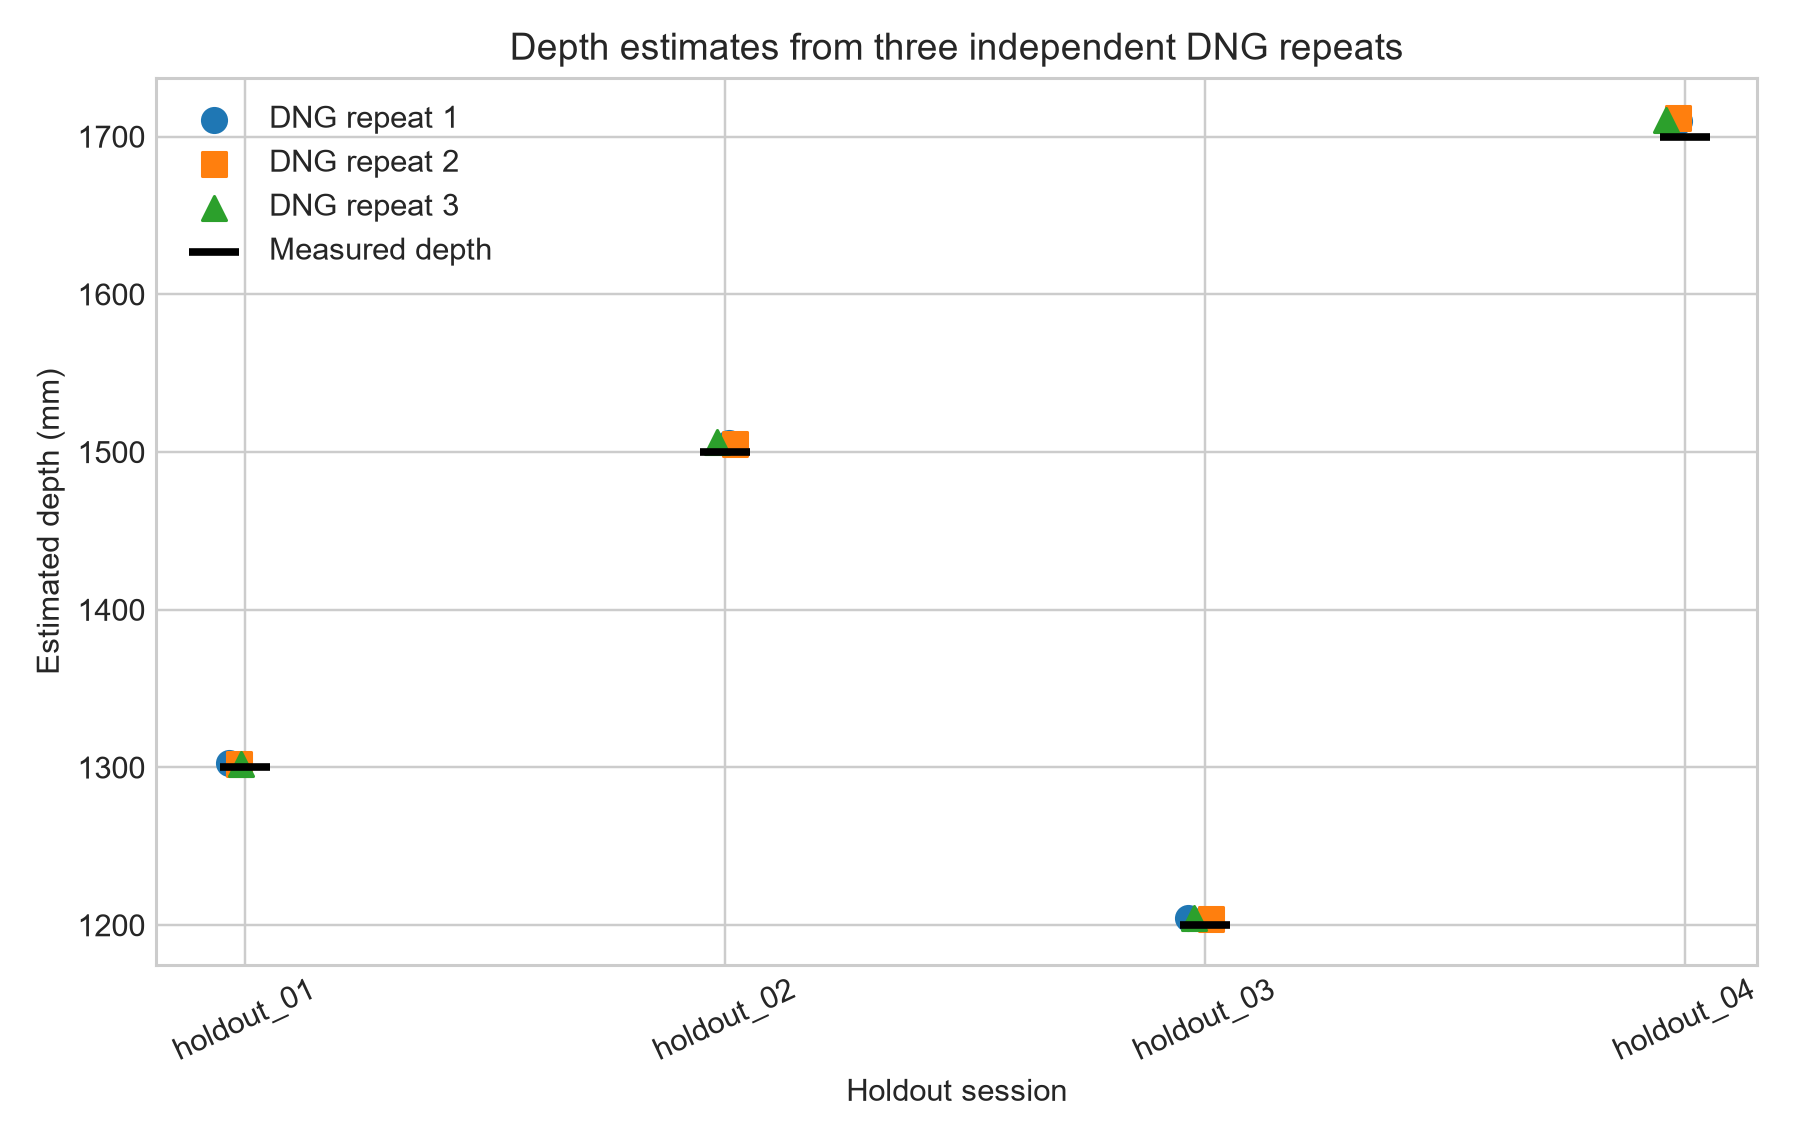

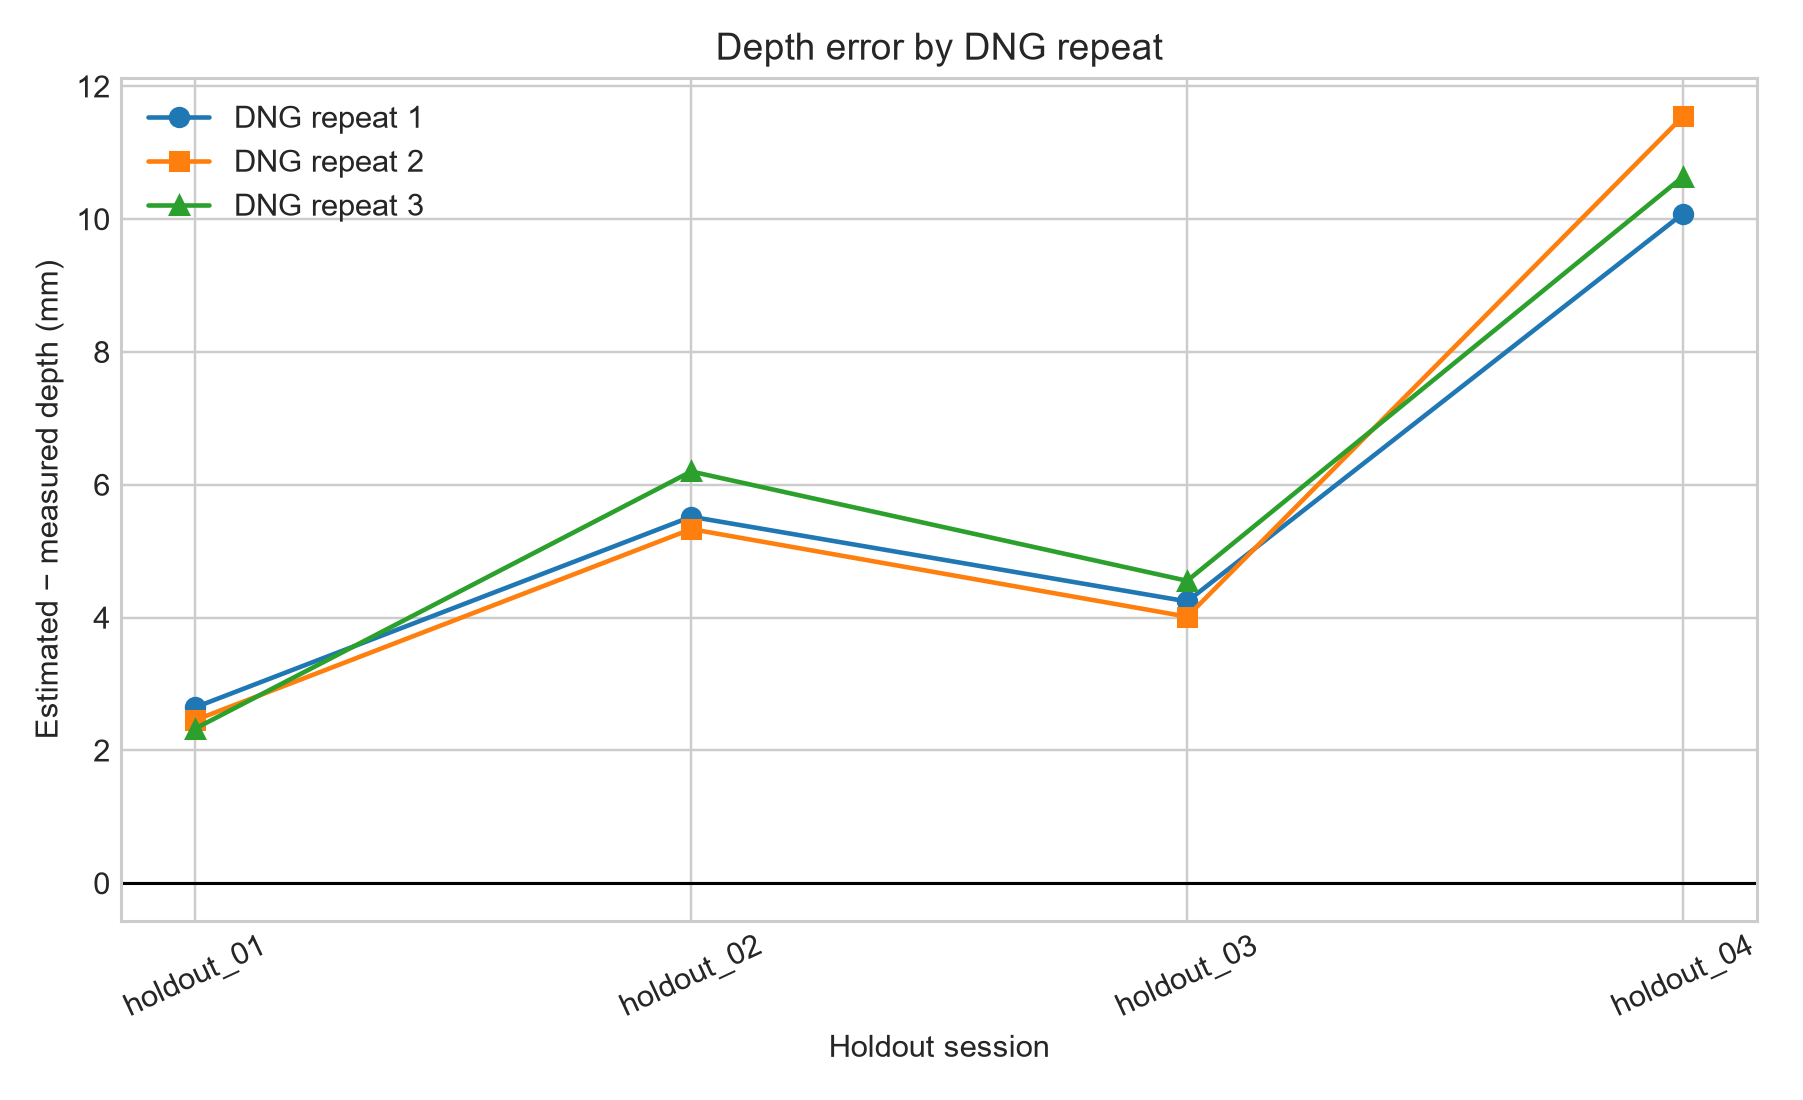

In [9]:
display(DisplayImage(filename=str(OUTPUT_DIR / '07_dng_repeat_depth_estimates.png')))
display(DisplayImage(filename=str(OUTPUT_DIR / '08_dng_repeat_depth_errors.png')))

## Interpretation caveats

- Calibration and holdout are separated correctly, but both use the same product box.
- Viewpoint-count and baseline studies use the PNG preview stream; the separate repeatability section uses all three DNG repeats.
- DNGs are decoded at half resolution, so their calibration coefficients must not be mixed with full-resolution PNG slope values.
- Bootstrap intervals describe variation among four holdout depths; within-depth DNG SD and the 2.77 x SD repeatability limit describe repeated-capture precision.
- The best tested setting is not a universal optimum: viewpoint subsets and baselines are a small discrete set.
